# Tarea

Para esta sesión trabajaremos con una base de datos sobre los precios de inmuebles en la ciudad de Ames, Iowa. La base se compone de 2930 registros y contiene un gran número de atributos.

Nuestro objetivo es generar un modelo que prediga de forma adecuada los precios de inmuebles, medidos con la variable `S​ale_Price​`.

## Ejercicio 1: Preparación del ambiente de trabajo

- Importe las librerías clásicas a utilizar.
- Para este ejercicio implementaremos árboles de regresión, por lo que deberá importar la clase ​DecisionTreeRegressor​.
- De manera adicional importe las funciones y clases necesarias para generar un desempeño de métricas en problemas de regresión, división de muestras y búsqueda de grilla con validación cruzada.
- Elimine la columna 'Unnamed: 0' cuando cargue los datos.

## Ejercicio 2: Feature engineering

- Identifique si el `​dtype` de cada `​pd.Serie` en nuestra base de datos se considera `'object'`​ o no. Para todas las variables que sean `​'object'`​, realice lo siguiente:
    + Genere una recodificación $k − 1$ en cada variable. Para efectos prácticos sólo necesitan eliminar una de las categorías, no se concentren en especificar la categoría a eliminar. Pueden utilizar la función con la opción `​drop_first` para ello.
    + Utilizando el método `​pd.concat`​, concatene a los atributos creados en la base de datos.
  
> **Tip:** No se olvide de eliminar los atributos recodificados, de esta forma evitará un aumento artificial del desempeño del modelo.

## Ejercicio 3: Primer modelo

- Genere muestras de entrenamiento y validación con `​'Sale_Price'` como vector objetivo y los atributos de la base de datos como matriz.
- Recuerde definir el porcentaje de casos en la muestra de validación y una semilla pseudoaleatoria.
- Posteriormente, entrene un árbol de regresión en la muestra de entrenamiento sin modificar los hiper parámetros. Reporte las principales métricas de desempeño.
- Comente sobre el desempeño.

## Ejercicio 4: Importancia relativa

- Implemente el método `​plot_importance` utilizado en la lectura para reportar la importancia relativa de los atributos.
- Comente sobre cuáles son los principales 10 atributos que afectan la predicción de `Sale_Price​`.
- Separe estos 10 atributos en una nueva base de datos, junto con el vector objetivo.
  
## Ejercicio 5: Refactorización del modelo y `picklingpd.get_dummies`

- En función de los atributos seleccionados en el ejercicio anterior, vuelva a generar conjuntos de entrenamiento y validación.
- **Dentro de los datos de entrenamiento** genere una búsqueda de grilla con `​GridSearchCV` utilizando los siguientes hiper parámetros:
    + **Máximo de atributos**:​ Evalúe todos los posibles atributos.
    + **Máximo de profundidad**:​ Entre 1 a 32.
    + **Validaciones cruzadas**:​ 5.
- Reporte la mejor combinación de hiper parámetros y su desempeño asociado. Compare el desempeño en la muestra de validación con el modelo por defecto. 

### Pickling

- Ahora generamos una serialización de nuestro modelo depurado, y nuestros conjuntos de entrenamiento y validación depurados. Para ello importe el módulo `​pickle​`.
- `pickle` contiene la función dump, que permite guardar el modelo desarrollado. La forma canónica para desarrollar el pickling es:

```python
import pickle
pickle.dump(<OBJETO_CON_EL_MODELO>, open('26-05-04_nombre-apellido.pkl','wb'))
```

- Envíe su modelo y conjuntos de entrenamiento a un compañero.

# Importación de librerias:

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Carga de datos

In [8]:
#Configuración visual 
plt.rcParams['figure.figsize'] = (10, 6)
plt.style.use('ggplot')

#Carga de los datos
df = pd.read_csv('ames_housing.csv')

#Eliminamos la columna 'Unnamed: 0' si existe
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])
elif df.columns[0] == 'Unnamed: 0' or df.columns[0] == '':
    #Alternativa por si la columna no tiene nombre en el CSV
    df = df.drop(df.columns[0], axis=1)

In [9]:
#Identificamos columnas tipo 'object'
cat_cols = df.select_dtypes(include=['object']).columns

#Generamos variables dummy con k-1 (drop_first=True)
df_dummies = pd.get_dummies(df[cat_cols], drop_first=True)

#Concatenar a la base de datos y eliminar las columnas originales tipo object
df = pd.concat([df.drop(columns=cat_cols), df_dummies], axis=1)

print(f"Dimensiones del dataset tras el Feature Engineering: {df.shape}")

Dimensiones del dataset tras el Feature Engineering: (2930, 305)


C:\Users\lukas\AppData\Local\Temp\ipykernel_27988\12695780.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


# Primer modelo

In [10]:
#Definir matriz de atributos (X) y vector objetivo (y)
X = df.drop(columns=['Sale_Price'])
y = df['Sale_Price']

#Dividir la muestra (30% validación, semilla 42 para reproducibilidad)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

#Instanciar y entrenar el modelo por defecto
default_tree = DecisionTreeRegressor(random_state=42)
default_tree.fit(X_train, y_train)

#Predicciones
y_pred_default = default_tree.predict(X_test)

#Reporte de métricas
rmse_default = np.sqrt(mean_squared_error(y_test, y_pred_default))
mae_default = mean_absolute_error(y_test, y_pred_default)
r2_default = r2_score(y_test, y_pred_default)

print("Desempeño del Modelo por Defecto")
print(f"RMSE: {rmse_default:.2f}")
print(f"MAE:  {mae_default:.2f}")
print(f"R2:   {r2_default:.4f}")

Desempeño del Modelo por Defecto
RMSE: 41256.28
MAE:  25405.21
R2:   0.7579


# Importancia relativa

C:\Users\lukas\AppData\Local\Temp\ipykernel_27988\4194004858.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Atributo', data=top_imp, palette='viridis')


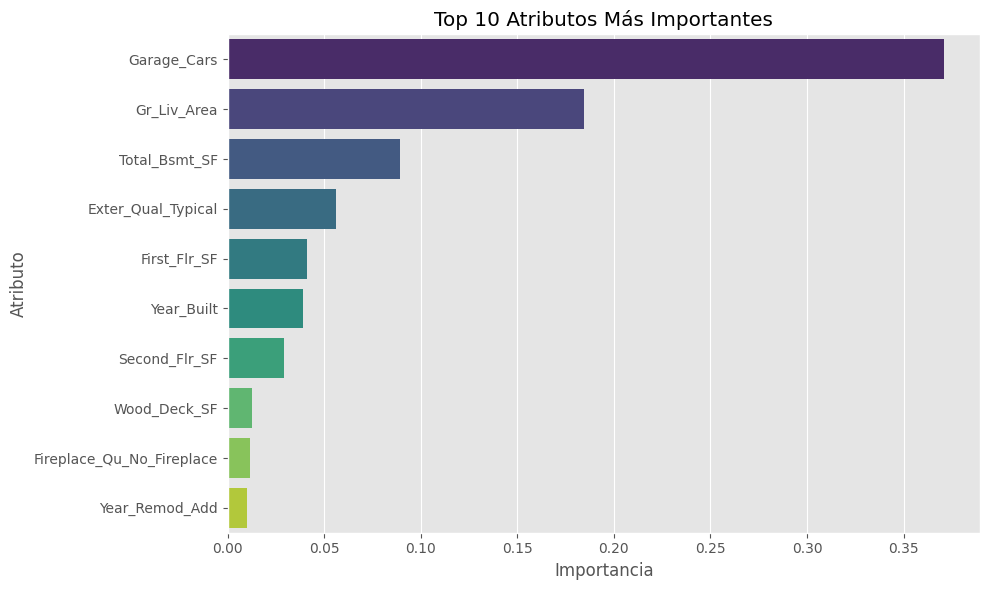

Los 10 atributos principales son:
['Garage_Cars', 'Gr_Liv_Area', 'Total_Bsmt_SF', 'Exter_Qual_Typical', 'First_Flr_SF', 'Year_Built', 'Second_Flr_SF', 'Wood_Deck_SF', 'Fireplace_Qu_No_Fireplace', 'Year_Remod_Add']


In [12]:
def plot_importance(modelo, columnas, max_features=10):
    """Grafica la importancia de atributos para un modelo de árbol."""
    importancias = modelo.feature_importances_
    
    #Crear dataframe y ordenar
    df_imp = pd.DataFrame({
        'Atributo': columnas,
        'Importancia': importancias
    }).sort_values(by='Importancia', ascending=False)
    
    #Seleccionar top N
    top_imp = df_imp.head(max_features)
    
    # Graficar
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Importancia', y='Atributo', data=top_imp, palette='viridis')
    plt.title(f'Top {max_features} Atributos Más Importantes')
    plt.tight_layout()
    plt.show()
    
    return top_imp['Atributo'].tolist()

#Extraer y plotear los top 10 atributos
top_10_features = plot_importance(default_tree, X_train.columns, max_features=10)

print(f"Los 10 atributos principales son:\n{top_10_features}")

#Crear nueva base de datos solo con los 10 atributos y el vector objetivo
df_top10 = df[top_10_features + ['Sale_Price']]

# Refactorización del modelo

In [ ]:
#Nueva división de muestras con la base reducida
X_top = df_top10.drop(columns=['Sale_Price'])
y_top = df_top10['Sale_Price']

X_train_top, X_test_top, y_train_top, y_test_top = train_test_split(
    X_top, y_top, test_size=0.3, random_state=42
)

#Definimos la grilla de hiperparámetros
#Máximo de atributos: 1 a 10 (porque ahora solo tenemos 10 features)
#Máximo de profundidad: 1 a 32
param_grid = {
    'max_features': range(1, X_train_top.shape[1] + 1), 
    'max_depth': range(1, 33)
}

#Búsqueda de grilla 
grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error', # GridSearchCV maximiza, por lo que usa MSE negativo
    n_jobs=-1
)

grid_search.fit(X_train_top, y_train_top)

#Reporte de mejores hiperparámetros
best_model = grid_search.best_estimator_
print("Mejores Hiperparámetros:")
print(grid_search.best_params_)

#Predicciones con el mejor modelo
y_pred_best = best_model.predict(X_test_top)

# Métricas del nuevo modelo
rmse_best = np.sqrt(mean_squared_error(y_test_top, y_pred_best))
mae_best = mean_absolute_error(y_test_top, y_pred_best)
r2_best = r2_score(y_test_top, y_pred_best)

print("\nDesempeño del Modelo Refactorizado (Top 10)")
print(f"RMSE: {rmse_best:.2f} (Vs Original: {rmse_default:.2f})")
print(f"MAE:  {mae_best:.2f} (Vs Original: {mae_default:.2f})")
print(f"R2:   {r2_best:.4f} (Vs Original: {r2_default:.4f})")

Mejores Hiperparámetros:
{'max_depth': 7, 'max_features': 5}

Desempeño del Modelo Refactorizado (Top 10)
RMSE: 37343.35 (Vs Original: 41256.28)
MAE:  24250.91 (Vs Original: 25405.21)
R2:   0.8016 (Vs Original: 0.7579)


In [16]:
#Guardamos el modelo depurado
with open('modelo_depurado.pkl', 'wb') as f:
    pickle.dump(best_model, f)

#Datos depurados
datos_depurados = {
    'X_train': X_train_top,
    'X_test': X_test_top,
    'y_train': y_train_top,
    'y_test': y_test_top
}

with open('26-05-04_nombre-apellido_datos.pkl', 'wb') as f:
    pickle.dump(datos_depurados, f)